# Regression Diagnostics and Model Assumptions

A regression model can have a high $R^2$ and still be wrong. Diagnostics check whether the model's
assumptions are plausible, whether a few points dominate the fit, and whether the coefficients can be
interpreted. This notebook uses ordinary least squares (OLS) on a deliberately imperfect dataset.

## Learning objectives

By the end of this notebook you can:

- check linearity, constant variance, residual normality, and independence;
- detect multicollinearity with correlations and variance inflation factors (VIF);
- identify leverage points and influential observations with Cook's distance;
- use robust standard errors, transformations, and robust regression as remedies;
- explain why predictive accuracy and valid inference are different goals.

## 1. The assumptions of linear regression

Classical OLS inference relies on several assumptions:

1. **Linearity:** the expected target is a linear function of the features.
2. **Independence:** observations are independent (important for time series and grouped data).
3. **Homoscedasticity:** the residual variance is constant across fitted values.
4. **Normality:** residuals are approximately normal, especially for small samples.
5. **No severe multicollinearity:** features are not nearly linear combinations of each other.

Diagnostics are evidence, not proof. A violation does not automatically invalidate predictions, but it
does affect confidence intervals, p-values, and interpretation.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from sklearn.linear_model import HuberRegressor

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

## 2. A dataset with realistic problems

We simulate a dataset with:

- a non-linear quadratic effect that the linear model omits;
- heteroscedastic noise that grows with $|x_1|$;
- correlated predictors $x_1$ and $x_2$ (multicollinearity);
- a handful of large outliers.

In [2]:
n = 300
x1 = rng.normal(0, 1, n)
x2 = 0.85 * x1 + rng.normal(0, 0.35, n)
x3 = rng.normal(0, 1, n)

noise = rng.normal(0, 0.6 + 0.8 * np.abs(x1), n)
y = 3.0 + 2.0 * x1 - 1.2 * x2 + 1.5 * x3 + 0.9 * x1 ** 2 + noise

outlier_idx = rng.choice(n, 6, replace=False)
y[outlier_idx] += rng.normal(14, 4, len(outlier_idx))

df = pd.DataFrame({"y": y, "x1": x1, "x2": x2, "x3": x3})
print(df.describe().round(2))
print("outlier rows:", outlier_idx)

            y      x1      x2      x3
count  300.00  300.00  300.00  300.00
mean     4.00   -0.04   -0.04   -0.08
std      3.58    0.93    0.88    1.01
min     -3.61   -2.57   -2.78   -2.67
25%      2.07   -0.67   -0.65   -0.79
50%      3.63   -0.09   -0.05   -0.04
75%      5.29    0.47    0.49    0.56
max     28.61    2.91    2.72    3.18
outlier rows: [ 61 155 125  31  52 122]


In [3]:
X = sm.add_constant(df[["x1", "x2", "x3"]])
model = sm.OLS(df["y"], X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.373
Model:                            OLS   Adj. R-squared:                  0.366
Method:                 Least Squares   F-statistic:                     58.64
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           8.83e-30
Time:                        22:28:06   Log-Likelihood:                -737.94
No. Observations:                 300   AIC:                             1484.
Df Residuals:                     296   BIC:                             1499.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.1876      0.165     25.328      0.0

The linear model reports a strong overall fit, but that does not tell us whether the functional form
is correct or whether a few points are driving the result. The residual diagnostics come next.

## 3. Residual diagnostics

The four standard plots are:

- **Residuals vs fitted:** should show no pattern and roughly constant spread.
- **Normal Q-Q:** residuals should fall near the diagonal.
- **Scale-location:** the square root of standardized residuals should have a flat trend.
- **Residual histogram:** a rough check for skew and heavy tails.

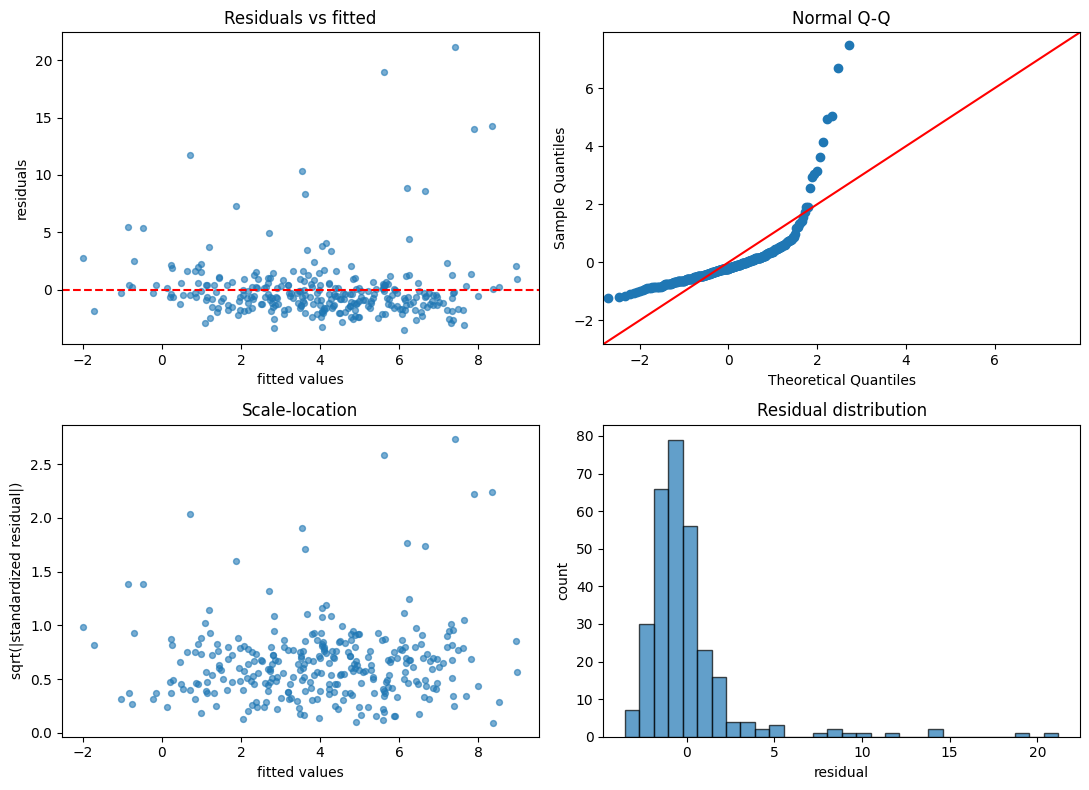

In [4]:
fitted = model.fittedvalues
resid = model.resid
std_resid = resid / np.std(resid, ddof=1)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].scatter(fitted, resid, s=18, alpha=0.6)
axes[0, 0].axhline(0, color="red", linestyle="--")
axes[0, 0].set_xlabel("fitted values")
axes[0, 0].set_ylabel("residuals")
axes[0, 0].set_title("Residuals vs fitted")

sm.qqplot(resid, line="45", fit=True, ax=axes[0, 1])
axes[0, 1].set_title("Normal Q-Q")

axes[1, 0].scatter(fitted, np.sqrt(np.abs(std_resid)), s=18, alpha=0.6)
axes[1, 0].set_xlabel("fitted values")
axes[1, 0].set_ylabel("sqrt(|standardized residual|)")
axes[1, 0].set_title("Scale-location")

axes[1, 1].hist(resid, bins=30, edgecolor="black", alpha=0.7)
axes[1, 1].set_xlabel("residual")
axes[1, 1].set_ylabel("count")
axes[1, 1].set_title("Residual distribution")

plt.tight_layout()
plt.show()

The curved pattern in the residual plot suggests a missing non-linear term. The widening spread
suggests heteroscedasticity. The Q-Q plot shows heavy tails, partly from the outliers. The linear
model is misspecified even though its $R^2$ is high.

## 4. Multicollinearity

Correlated features make individual coefficients unstable: the model can trade off one coefficient
against another without changing predictions much. The **variance inflation factor** for feature $j$
is

$$ \mathrm{VIF}_j = \frac{1}{1 - R_j^2} $$

where $R_j^2$ comes from regressing feature $j$ on the other features. A VIF above 5 is worth
investigating; above 10 is usually severe.

In [5]:
corr = df[["x1", "x2", "x3"]].corr()
print(corr.round(3))

X_vif = df[["x1", "x2", "x3"]]
vif = pd.DataFrame({
    "feature": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
print(vif.round(2))

       x1     x2     x3
x1  1.000  0.914 -0.073
x2  0.914  1.000 -0.120
x3 -0.073 -0.120  1.000
  feature   VIF
0      x1  6.15
1      x2  6.21
2      x3  1.02


$X_1$ and $X_2$ have a high VIF because they were generated to be correlated. This does not hurt
prediction much, but it makes the coefficient estimates and their standard errors hard to interpret.
Dropping one feature, combining them, or using regularization are common remedies.

## 5. Leverage and influential observations

**Leverage** measures how far an observation's features are from the center of the feature space.
**Cook's distance** combines leverage and residual size to measure how much the fitted coefficients
change when an observation is removed. A common screening threshold is $4/n$.

In [6]:
influence = model.get_influence()
leverage = influence.hat_matrix_diag
cooks = influence.cooks_distance[0]
threshold = 4 / len(df)

summary = pd.DataFrame({
    "leverage": leverage,
    "cooks_distance": cooks,
    "residual": resid,
    "y": df["y"],
})
print(summary.sort_values("cooks_distance", ascending=False).head(8).round(3))
print("Cook's distance threshold (4/n):", round(threshold, 4))

     leverage  cooks_distance  residual       y
52      0.020           0.232    18.995  24.615
31      0.029           0.188    14.024  21.911
125     0.012           0.171    21.195  28.610
155     0.022           0.146    14.290  22.629
139     0.049           0.116     8.310  11.932
248     0.038           0.100     8.857  15.064
122     0.022           0.096    11.740  12.449
226     0.036           0.087     8.583  15.237
Cook's distance threshold (4/n): 0.0133


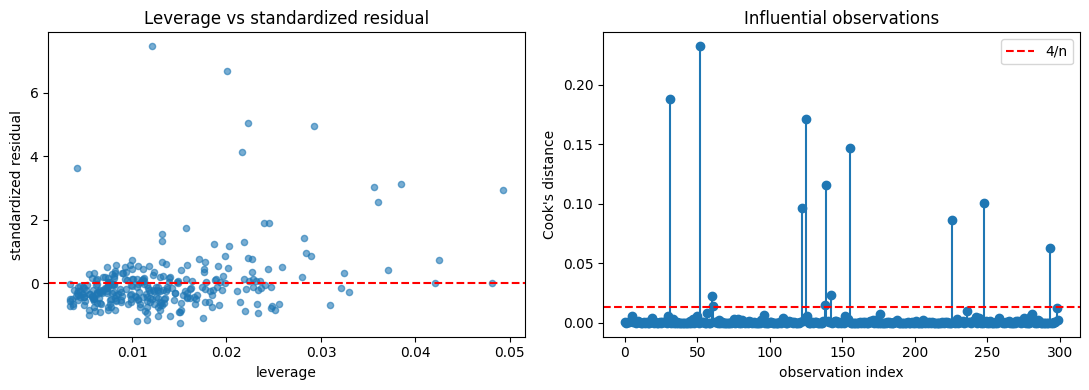

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(leverage, std_resid, s=20, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("leverage")
axes[0].set_ylabel("standardized residual")
axes[0].set_title("Leverage vs standardized residual")

axes[1].stem(np.arange(len(df)), cooks, basefmt=" ")
axes[1].axhline(threshold, color="red", linestyle="--", label="4/n")
axes[1].set_xlabel("observation index")
axes[1].set_ylabel("Cook's distance")
axes[1].set_title("Influential observations")
axes[1].legend()

plt.tight_layout()
plt.show()

Points with high leverage and large residuals are the most dangerous. Do not delete observations just
because they are influential: investigate whether they are data errors, a different population, or
genuine extreme events. Report the sensitivity of conclusions to their removal.

## 6. Formal tests

- **Breusch-Pagan** tests whether residual variance depends on the features.
- **Shapiro-Wilk** tests residual normality (sensitive in large samples).
- **Durbin-Watson** tests first-order autocorrelation, mainly relevant for ordered/time-series data.

Tests are auxiliary evidence. With large samples, small and practically unimportant deviations can be
statistically significant.

In [8]:
bp_stat, bp_pvalue, bp_f, bp_f_pvalue = het_breuschpagan(resid, model.model.exog)
shapiro_stat, shapiro_pvalue = stats.shapiro(resid)
dw = durbin_watson(resid)

print(f"Breusch-Pagan statistic: {bp_stat:.3f}, p-value: {bp_pvalue:.5f}")
print(f"Shapiro-Wilk statistic:  {shapiro_stat:.3f}, p-value: {shapiro_pvalue:.5f}")
print(f"Durbin-Watson:            {dw:.3f}")

Breusch-Pagan statistic: 5.917, p-value: 0.11570
Shapiro-Wilk statistic:  0.628, p-value: 0.00000
Durbin-Watson:            2.007


The Breusch-Pagan result rejects constant variance, and the Shapiro-Wilk result rejects normality.
Durbin-Watson is not meaningful here because the rows have no natural time order; it is included to
show the workflow.

## 7. Remedies

A reasonable response is not to keep the misspecified model. Options include:

- add the missing quadratic term;
- use robust (heteroscedasticity-consistent) standard errors;
- use a robust loss such as Huber regression when outliers are a concern;
- transform the target or features when the relationship suggests it.

Below we compare the original model, a model with $x_1^2$, and the quadratic model with HC3 robust
standard errors.

In [9]:
df["x1_squared"] = df["x1"] ** 2
X_quad = sm.add_constant(df[["x1", "x2", "x3", "x1_squared"]])
model_quad = sm.OLS(df["y"], X_quad).fit()
model_robust = model_quad.get_robustcov_results(cov_type="HC3")

comparison = pd.DataFrame({
    "model": ["linear", "linear + x1^2", "linear + x1^2 (HC3)"],
    "R2": [model.rsquared, model_quad.rsquared, model_quad.rsquared],
    "adj_R2": [model.rsquared_adj, model_quad.rsquared_adj, model_quad.rsquared_adj],
    "AIC": [model.aic, model_quad.aic, model_quad.aic],
})
print(comparison.round(3))

                 model     R2  adj_R2       AIC
0               linear  0.373   0.366  1483.886
1        linear + x1^2  0.507   0.501  1413.517
2  linear + x1^2 (HC3)  0.507   0.501  1413.517


In [10]:
print("Quadratic model coefficients:")
print(model_quad.params.round(3))
print()
print("HC3 robust standard errors:")
print(pd.Series(model_robust.bse, index=model_quad.params.index).round(3))

Quadratic model coefficients:
const         3.282
x1            2.296
x2           -1.459
x3            1.780
x1_squared    1.039
dtype: float64

HC3 robust standard errors:
const         0.179
x1            0.293
x2            0.300
x3            0.241
x1_squared    0.127
dtype: float64


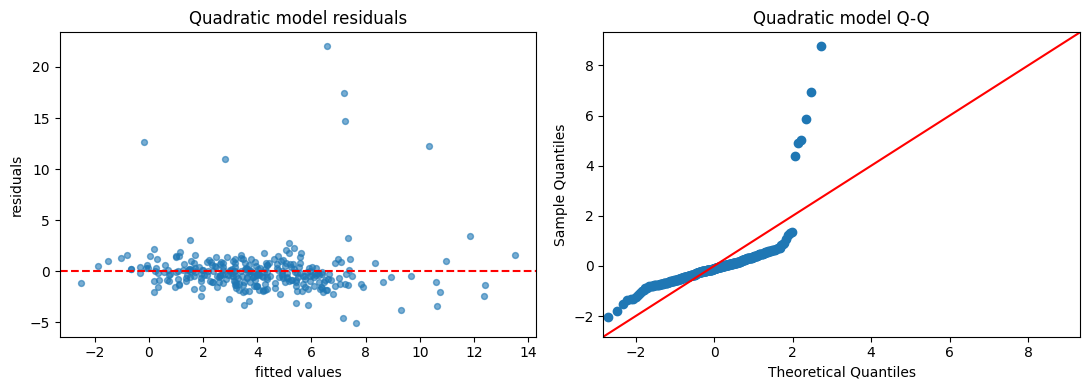

In [11]:
resid_quad = model_quad.resid
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(model_quad.fittedvalues, resid_quad, s=18, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("fitted values")
axes[0].set_ylabel("residuals")
axes[0].set_title("Quadratic model residuals")

sm.qqplot(resid_quad, line="45", fit=True, ax=axes[1])
axes[1].set_title("Quadratic model Q-Q")

plt.tight_layout()
plt.show()

Adding $x_1^2$ removes the obvious curvature, but the outliers and heteroscedasticity remain. Robust
standard errors address inference; Huber regression can reduce the influence of outliers on the
coefficient estimates.

In [12]:
features = ["x1", "x2", "x3", "x1_squared"]
huber = HuberRegressor(epsilon=1.35, alpha=0.0, max_iter=500)
huber.fit(df[features], df["y"])

print("OLS quadratic coefficients:")
print(model_quad.params.round(3))
print()
print("Huber coefficients (intercept last):")
print(np.round(huber.coef_, 3), "intercept:", round(huber.intercept_, 3))

OLS quadratic coefficients:
const         3.282
x1            2.296
x2           -1.459
x3            1.780
x1_squared    1.039
dtype: float64

Huber coefficients (intercept last):
[ 2.34  -1.619  1.486  1.041] intercept: 2.988


Diagnostics should be part of the modeling loop, not a final checkbox. Fit, inspect, revise, and
document what changed. For predictive tasks, validate on held-out data; for inferential tasks, report
uncertainty and sensitivity to modeling choices.

## 8. Summary

- High $R^2$ does not validate linearity, independence, or constant variance.
- Residual plots reveal curvature, heteroscedasticity, and heavy tails.
- VIF detects multicollinearity; it affects interpretation more than raw prediction.
- Cook's distance combines leverage and residual size to flag influential points.
- Breusch-Pagan, Shapiro-Wilk, and Durbin-Watson provide formal checks.
- Transformations, robust standard errors, and robust regression are practical remedies.

## Exercises

1. Remove the six outliers and refit the linear model. How do the coefficients change?
2. Add a log transformation of a positive target and compare residual diagnostics.
3. Compute VIF after dropping $x_2$ and explain the change.
4. Use weighted least squares with weights proportional to $1/(1+|x_1|)$ and compare standard errors.
5. Explain why an influential point is not necessarily a data error.